In [1]:
import numpy as np

np.random.seed(42)

# Objective Function: Minimize Spring Weight with Penalty for Constraint Violations
# Variables x = [wire diameter (d), mean coil diameter (D), active coils (N)]
def objective_spring(x):
    d, D, N = x[0], x[1], x[2]
    weight = (N + 2) * D * (d ** 2)

    # Nonlinear constraints (shear stress, surge frequency, deflection, geometry)
    g1 = 1 - (D**3 * N) / (71785 * d**4)
    g2 = (4 * D**2 - d * D) / (12566 * (D * d**3 - d**4)) + 1 / (5108 * d**2) - 1
    g3 = 1 - (140.45 * d) / (D**2 * N)
    g4 = (d + D) / 1.5 - 1

    penalty = sum(1e5 * (g ** 2) for g in [g1, g2, g3, g4] if g > 0)
    return weight + penalty

def gwo_optimize(obj_func, lb, ub, dim, n_wolves=50, max_iter=1000):
    alpha_pos, beta_pos, delta_pos = np.zeros(dim), np.zeros(dim), np.zeros(dim)
    alpha_score, beta_score, delta_score = float("inf"), float("inf"), float("inf")

    positions = np.random.uniform(0, 1, (n_wolves, dim)) * (ub - lb) + lb

    for t in range(max_iter):
        for i in range(n_wolves):
            positions[i] = np.clip(positions[i], lb, ub)
            fitness = obj_func(positions[i])

            # Update Alpha, Beta, and Delta leaders
            if fitness < alpha_score:
                delta_score, delta_pos = beta_score, beta_pos.copy()
                beta_score, beta_pos = alpha_score, alpha_pos.copy()
                alpha_score, alpha_pos = fitness, positions[i].copy()
            elif fitness < beta_score:
                delta_score, delta_pos = beta_score, beta_pos.copy()
                beta_score, beta_pos = fitness, positions[i].copy()
            elif fitness < delta_score:
                delta_score, delta_pos = fitness, positions[i].copy()

        a = 2 - t * (2 / max_iter)  # Linearly decreases from 2 to 0

        # Update positions of all wolves based on top 3 leaders
        for i in range(n_wolves):
            for j in range(dim):
                r1, r2 = np.random.random(), np.random.random()
                A1, C1 = 2 * a * r1 - a, 2 * r2
                X1 = alpha_pos[j] - A1 * abs(C1 * alpha_pos[j] - positions[i, j])

                r1, r2 = np.random.random(), np.random.random()
                A2, C2 = 2 * a * r1 - a, 2 * r2
                X2 = beta_pos[j] - A2 * abs(C2 * beta_pos[j] - positions[i, j])

                r1, r2 = np.random.random(), np.random.random()
                A3, C3 = 2 * a * r1 - a, 2 * r2
                X3 = delta_pos[j] - A3 * abs(C3 * delta_pos[j] - positions[i, j])

                positions[i, j] = (X1 + X2 + X3) / 3.0

    return alpha_pos, alpha_score

# Search space bounds for [d, D, N]
lb = np.array([0.05, 0.25, 2.0])
ub = np.array([2.0, 1.3, 15.0])

best_x, best_val = gwo_optimize(objective_spring, lb, ub, dim=3)
print(f"Optimal Design [d, D, N]: {best_x}")
print(f"Minimum Spring Weight: {best_val:.6f}")


Optimal Design [d, D, N]: [ 0.05071385  0.33362235 12.78781803]
Minimum Spring Weight: 0.012689


In [2]:
import matplotlib.pyplot as plt

def gwo_optimize_with_history(obj_func, lb, ub, dim, n_wolves=50, max_iter=1000):
    alpha_pos, beta_pos, delta_pos = np.zeros(dim), np.zeros(dim), np.zeros(dim)
    alpha_score, beta_score, delta_score = float("inf"), float("inf"), float("inf")

    positions = np.random.uniform(0, 1, (n_wolves, dim)) * (ub - lb) + lb
    convergence_history = []

    # Checkpoints to log
    checkpoints = [10, 30, 50, 75, 100, 200, 500, 1000]

    for t in range(max_iter):
        for i in range(n_wolves):
            positions[i] = np.clip(positions[i], lb, ub)
            fitness = obj_func(positions[i])

            # Update Alpha, Beta, and Delta leaders
            if fitness < alpha_score:
                delta_score, delta_pos = beta_score, beta_pos.copy()
                beta_score, beta_pos = alpha_score, alpha_pos.copy()
                alpha_score, alpha_pos = fitness, positions[i].copy()
            elif fitness < beta_score:
                delta_score, delta_pos = beta_score, beta_pos.copy()
                beta_score, beta_pos = fitness, positions[i].copy()
            elif fitness < delta_score:
                delta_score, delta_pos = fitness, positions[i].copy()

        a = 2 - t * (2 / max_iter)  # Linearly decreases from 2 to 0

        # Update positions of all wolves based on top 3 leaders
        for i in range(n_wolves):
            for j in range(dim):
                r1, r2 = np.random.random(), np.random.random()
                A1, C1 = 2 * a * r1 - a, 2 * r2
                X1 = alpha_pos[j] - A1 * abs(C1 * alpha_pos[j] - positions[i, j])

                r1, r2 = np.random.random(), np.random.random()
                A2, C2 = 2 * a * r1 - a, 2 * r2
                X2 = beta_pos[j] - A2 * abs(C2 * beta_pos[j] - positions[i, j])

                r1, r2 = np.random.random(), np.random.random()
                A3, C3 = 2 * a * r1 - a, 2 * r2
                X3 = delta_pos[j] - A3 * abs(C3 * delta_pos[j] - positions[i, j])

                positions[i, j] = (X1 + X2 + X3) / 3.0

        convergence_history.append(alpha_score)

        # Print progress at checkpoints (1-based index)
        iteration_num = t + 1
        if iteration_num in checkpoints:
            print(f"Iteration {iteration_num:4d}: Best Score = {alpha_score:.8f} | Best Position = {alpha_pos}")

    return alpha_pos, alpha_score, convergence_history

# Run the optimization tracking history
np.random.seed(42)
best_x_hist, best_val_hist, convergence = gwo_optimize_with_history(objective_spring, lb, ub, dim=3, max_iter=1000)

Iteration   10: Best Score = 0.02279353 | Best Position = [0.06723235 0.7997977  4.30485004]
Iteration   30: Best Score = 0.01657690 | Best Position = [0.05989389 0.55659468 6.30231489]
Iteration   50: Best Score = 0.01428070 | Best Position = [0.05582503 0.46351345 7.88619517]
Iteration   75: Best Score = 0.01399341 | Best Position = [0.05693467 0.47413966 7.10465644]
Iteration  100: Best Score = 0.01395974 | Best Position = [0.05584721 0.45376068 7.86387426]
Iteration  200: Best Score = 0.01294591 | Best Position = [ 0.05        0.31722883 14.32375293]
Iteration  500: Best Score = 0.01284300 | Best Position = [ 0.05121352  0.34381114 12.24220609]
Iteration 1000: Best Score = 0.01268856 | Best Position = [ 0.05071385  0.33362235 12.78781803]


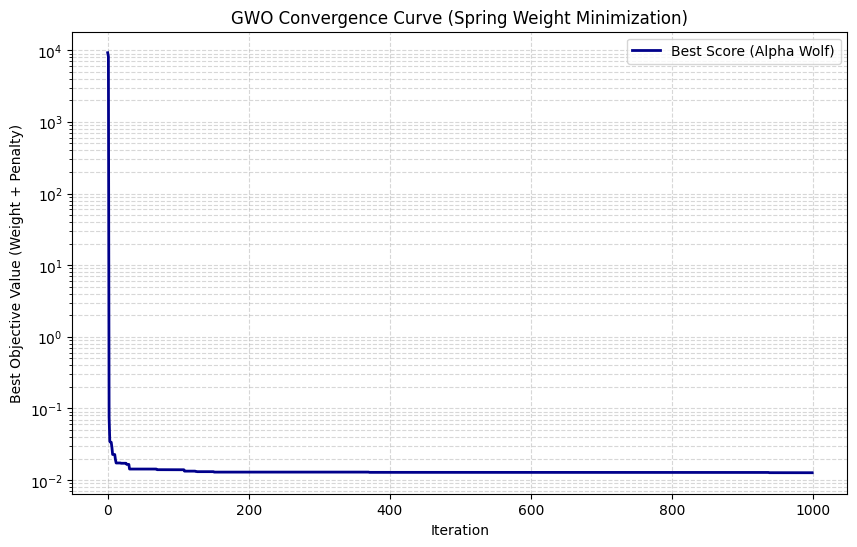

In [3]:
# Plotting convergence curve
plt.figure(figsize=(10, 6))
plt.plot(convergence, label="Best Score (Alpha Wolf)", color="darkblue", linewidth=2)
plt.title("GWO Convergence Curve (Spring Weight Minimization)")
plt.xlabel("Iteration")
plt.ylabel("Best Objective Value (Weight + Penalty)")
plt.yscale("log") # Log scale helps visualize changes across magnitudes
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()